# Credit Card Default Risk: Scorecard, Expected Loss and Cutoff Policy

Mini project on the UCI "Default of Credit Card Clients" dataset (30,000 credit card customers from Taiwan, 2005).

**What I want to do in this project**

1. Build a PD (probability of default) model the way banks do it, using WoE/IV binning and logistic regression
2. Turn the PD into a credit score and group customers into risk grades
3. Validate the model with AUC, Gini, KS and PSI
4. Calculate Expected Loss = PD x LGD x EAD
5. Suggest a score cutoff for approvals and see what happens under a stress scenario

**Rough mapping to Basel / FRM ideas**

| Step in notebook | Risk management idea |
|---|---|
| WoE, IV, logistic regression | Credit scoring, application/behaviour scorecards |
| AUC, Gini, KS, PSI | Model validation and monitoring |
| PD x LGD x EAD | Expected loss (Basel IRB / provisioning) |
| Cutoff analysis | Credit policy |
| PD multiplier | Simple stress testing |

Data: download `UCI_Credit_Card.csv` from Kaggle ("Default of Credit Card Clients Dataset") and keep it in the same folder as this notebook.

## 1. Setup and loading data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.figsize'] = (7, 4)

In [ ]:
DATA_PATH = 'UCI_Credit_Card.csv'

df = pd.read_csv(DATA_PATH)

# column names are slightly different in the kaggle and uci versions, so making them the same
df = df.rename(columns={'default.payment.next.month': 'default',
                        'default payment next month': 'default',
                        'PAY_1': 'PAY_0'})
df = df.drop(columns=['ID'], errors='ignore')

print(df.shape)
df.head()

(30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,"20,000.000",2,2,1,24,2,2,-1,-1,-2,-2,"3,913.000","3,102.000",689.000,0.000,0.000,0.000,0.000,689.000,0.000,0.000,0.000,0.000,1
1,"120,000.000",2,2,2,26,-1,2,0,0,0,2,"2,682.000","1,725.000","2,682.000","3,272.000","3,455.000","3,261.000",0.000,"1,000.000","1,000.000","1,000.000",0.000,"2,000.000",1
2,"90,000.000",2,2,2,34,0,0,0,0,0,0,"29,239.000","14,027.000","13,559.000","14,331.000","14,948.000","15,549.000","1,518.000","1,500.000","1,000.000","1,000.000","1,000.000","5,000.000",0
3,"50,000.000",2,2,1,37,0,0,0,0,0,0,"46,990.000","48,233.000","49,291.000","28,314.000","28,959.000","29,547.000","2,000.000","2,019.000","1,200.000","1,100.000","1,069.000","1,000.000",0
4,"50,000.000",1,2,1,57,-1,0,-1,0,0,0,"8,617.000","5,670.000","35,835.000","20,940.000","19,146.000","19,131.000","2,000.000","36,681.000","10,000.000","9,000.000",689.000,679.000,0


Quick note on the columns:

- `LIMIT_BAL`: credit limit (NT$)
- `PAY_0` to `PAY_6`: repayment status for the last 6 months (Sept back to April). `-1` = paid duly, `0` = revolving credit (paid minimum), `1` = 1 month late, `2` = 2 months late and so on. `-2` = no consumption
- `BILL_AMT1-6`: bill statement amounts, `PAY_AMT1-6`: amounts paid
- `default`: 1 if the customer defaulted the next month (this is my target)

In Basel terms, default is normally 90+ days past due. This dataset is a simplified version, so I am treating the target as the default flag.

## 2. Data cleaning

In [ ]:
print(df.isnull().sum().sum(), 'missing values')
print(df.duplicated().sum(), 'duplicate rows')   # not dropping these, they could be different customers with similar profiles

# EDUCATION has undocumented values (0, 5, 6) and MARRIAGE has 0, so grouping them into 'others'
print(df['EDUCATION'].value_counts().sort_index().to_dict())
print(df['MARRIAGE'].value_counts().sort_index().to_dict())

df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})
df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})

print('\noverall default rate:', round(df['default'].mean(), 4))

0 missing values
35 duplicate rows
{0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
{0: 54, 1: 13659, 2: 15964, 3: 323}

overall default rate: 0.2212


The overall default rate is the **portfolio bad rate**. It is a very basic risk metric but everything else gets compared to it. The classes are imbalanced (roughly 1 bad in 4 or 5), so I will use stratified splitting and I won't use accuracy as a metric.

## 3. Exploratory analysis (default rate by segment)

In [ ]:
def rate_by(col, bins=None):
    x = pd.cut(df[col], bins) if bins is not None else df[col]
    out = df.groupby(x, observed=True)['default'].agg(['count', 'mean'])
    return out.rename(columns={'mean': 'default_rate'})

print(rate_by('EDUCATION'), '\n')
print(rate_by('AGE', [20, 30, 40, 50, 60, 80]), '\n')
print(rate_by('LIMIT_BAL', [0, 50000, 100000, 200000, 400000, 1000000]))

           count  default_rate
EDUCATION                     
1          10585         0.192
2          14030         0.237
3           4917         0.252
4            468         0.071 

          count  default_rate
AGE                          
(20, 30]  11013         0.224
(30, 40]  10713         0.204
(40, 50]   6005         0.233
(50, 60]   1997         0.252
(60, 80]    272         0.268 

                   count  default_rate
LIMIT_BAL                             
(0, 50000]          7676         0.318
(50000, 100000]     4822         0.258
(100000, 200000]    7880         0.195
(200000, 400000]    7818         0.153
(400000, 1000000]   1804         0.120


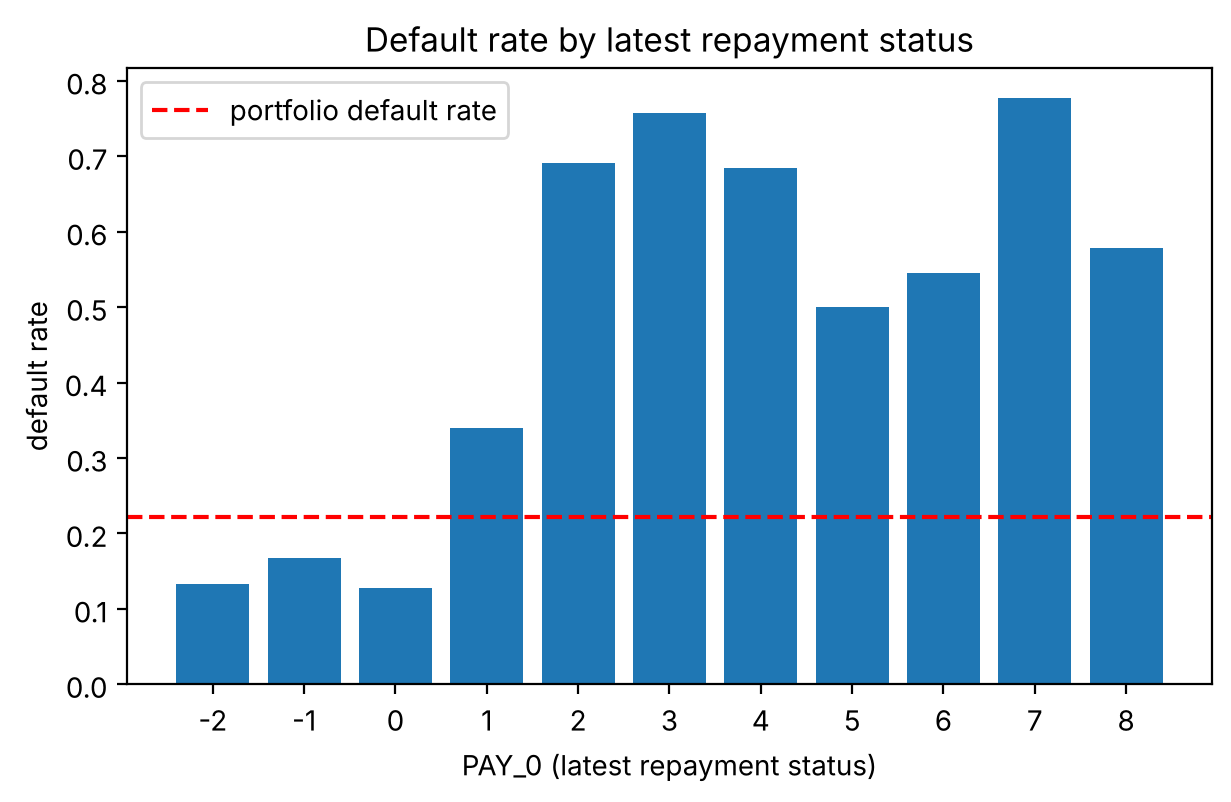

In [ ]:
pay0 = rate_by('PAY_0')
plt.bar(pay0.index.astype(str), pay0['default_rate'])
plt.axhline(df['default'].mean(), color='red', linestyle='--', label='portfolio default rate')
plt.xlabel('PAY_0 (latest repayment status)')
plt.ylabel('default rate')
plt.title('Default rate by latest repayment status')
plt.legend()
plt.show()

The default rate rises quickly once a customer is even 1-2 months late. This makes sense because past delinquency is the strongest signal in most behavioural scorecards. I expect PAY_0 to come out as the top variable in the IV step.

## 4. Feature engineering

Besides the raw columns I made a few features that a risk analyst would normally look at:

- `max_delay`: worst repayment status in the last 6 months
- `n_late_months`: number of months with a delay
- `utilization`: latest bill / credit limit
- `pay_ratio`: total paid / total billed (capped at 1)
- `avg_bill`, `avg_pay_amt`: 6 month averages

For the PAY columns I clipped values to the range -1 to 4 because the very high delays have very few customers.

In [ ]:
pay_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
bill_cols = [f'BILL_AMT{i}' for i in range(1, 7)]
amt_cols = [f'PAY_AMT{i}' for i in range(1, 7)]

feat = df.copy()
feat[pay_cols] = feat[pay_cols].clip(lower=-1, upper=4)

feat['max_delay'] = feat[pay_cols].max(axis=1)
feat['n_late_months'] = (feat[pay_cols] > 0).sum(axis=1)
feat['avg_bill'] = df[bill_cols].mean(axis=1)
feat['avg_pay_amt'] = df[amt_cols].mean(axis=1)
feat['utilization'] = (df['BILL_AMT1'] / df['LIMIT_BAL']).clip(0, 1.5)

total_billed = df[bill_cols].clip(lower=0).sum(axis=1).replace(0, np.nan)
feat['pay_ratio'] = (df[amt_cols].sum(axis=1) / total_billed).fillna(1).clip(0, 1)

candidates = ['LIMIT_BAL', 'AGE', 'SEX', 'EDUCATION', 'MARRIAGE'] + pay_cols + \
             ['max_delay', 'n_late_months', 'avg_bill', 'avg_pay_amt', 'utilization', 'pay_ratio']
print(len(candidates), 'candidate variables')

17 candidate variables


## 5. Train / test split

70/30 split, stratified on the default flag. All the binning and model fitting below uses **only the training data**, the test set is kept aside for validation and for the expected loss part.

In [ ]:
train, test = train_test_split(feat, test_size=0.3, stratify=feat['default'], random_state=42)
print(train.shape, test.shape)
print('train default rate:', round(train['default'].mean(), 4), '| test default rate:', round(test['default'].mean(), 4))

(21000, 30) (9000, 30)
train default rate: 0.2212 | test default rate: 0.2212


## 6. WoE and IV (variable selection)

This is the standard approach for scorecards. Each variable is split into bins and for every bin:

- `WoE = ln( % of goods in bin / % of bads in bin )`. Positive WoE means the bin is safer than average, negative means riskier.
- `IV = sum( (% goods - % bads) x WoE )`. This gives one number per variable showing how well it separates good and bad customers.

Rule of thumb that I found for IV:

| IV | Predictive power |
|---|---|
| < 0.02 | useless |
| 0.02 - 0.1 | weak |
| 0.1 - 0.3 | medium |
| 0.3 - 0.5 | strong |
| > 0.5 | too good, check for leakage |

Variables with many values are cut into quantile bins (max 6). Variables with few values (like PAY columns, SEX) are used as they are. I add 0.5 to the counts so that a bin with zero goods or bads doesn't give an infinite WoE.

In [ ]:
def make_woe_map(data, col, target='default', max_bins=6):
    x, y = data[col], data[target]

    if x.nunique() > 10:
        _, edges = pd.qcut(x, q=max_bins, retbins=True, duplicates='drop')
        edges = edges.astype(float)
        edges[0], edges[-1] = -np.inf, np.inf
        bin_id = pd.cut(x, bins=edges, labels=False)
        names = [f'({edges[i]:,.2f}, {edges[i+1]:,.2f}]' for i in range(len(edges) - 1)]
        kind = 'num'
    else:
        edges, bin_id, kind = None, x, 'cat'

    t = pd.DataFrame({'bin': bin_id, 'y': y}).groupby('bin')['y'].agg(['count', 'sum'])
    t.columns = ['total', 'bad']
    t['good'] = t['total'] - t['bad']
    t['pct_good'] = (t['good'] + 0.5) / (t['good'].sum() + 0.5 * len(t))
    t['pct_bad'] = (t['bad'] + 0.5) / (t['bad'].sum() + 0.5 * len(t))
    t['bad_rate'] = t['bad'] / t['total']
    t['woe'] = np.log(t['pct_good'] / t['pct_bad'])
    t['iv'] = (t['pct_good'] - t['pct_bad']) * t['woe']
    t['range'] = [names[int(i)] for i in t.index] if kind == 'num' else t.index.astype(str)

    return {'col': col, 'kind': kind, 'edges': edges, 'table': t, 'iv': t['iv'].sum()}


def apply_woe(x, m):
    # converts raw values into woe values using the map built on train
    if m['kind'] == 'num':
        x = pd.Series(pd.cut(x, bins=m['edges'], labels=False), index=x.index)
    return x.map(m['table']['woe']).fillna(0)


maps = {c: make_woe_map(train, c) for c in candidates}
iv_df = pd.DataFrame({'IV': {c: m['iv'] for c, m in maps.items()}}).sort_values('IV', ascending=False)
iv_df

,IV
n_late_months,0.892
PAY_0,0.890
max_delay,0.817
PAY_2,0.558
PAY_3,0.420
PAY_4,0.369
PAY_5,0.343
PAY_6,0.301
avg_pay_amt,0.180
LIMIT_BAL,0.174


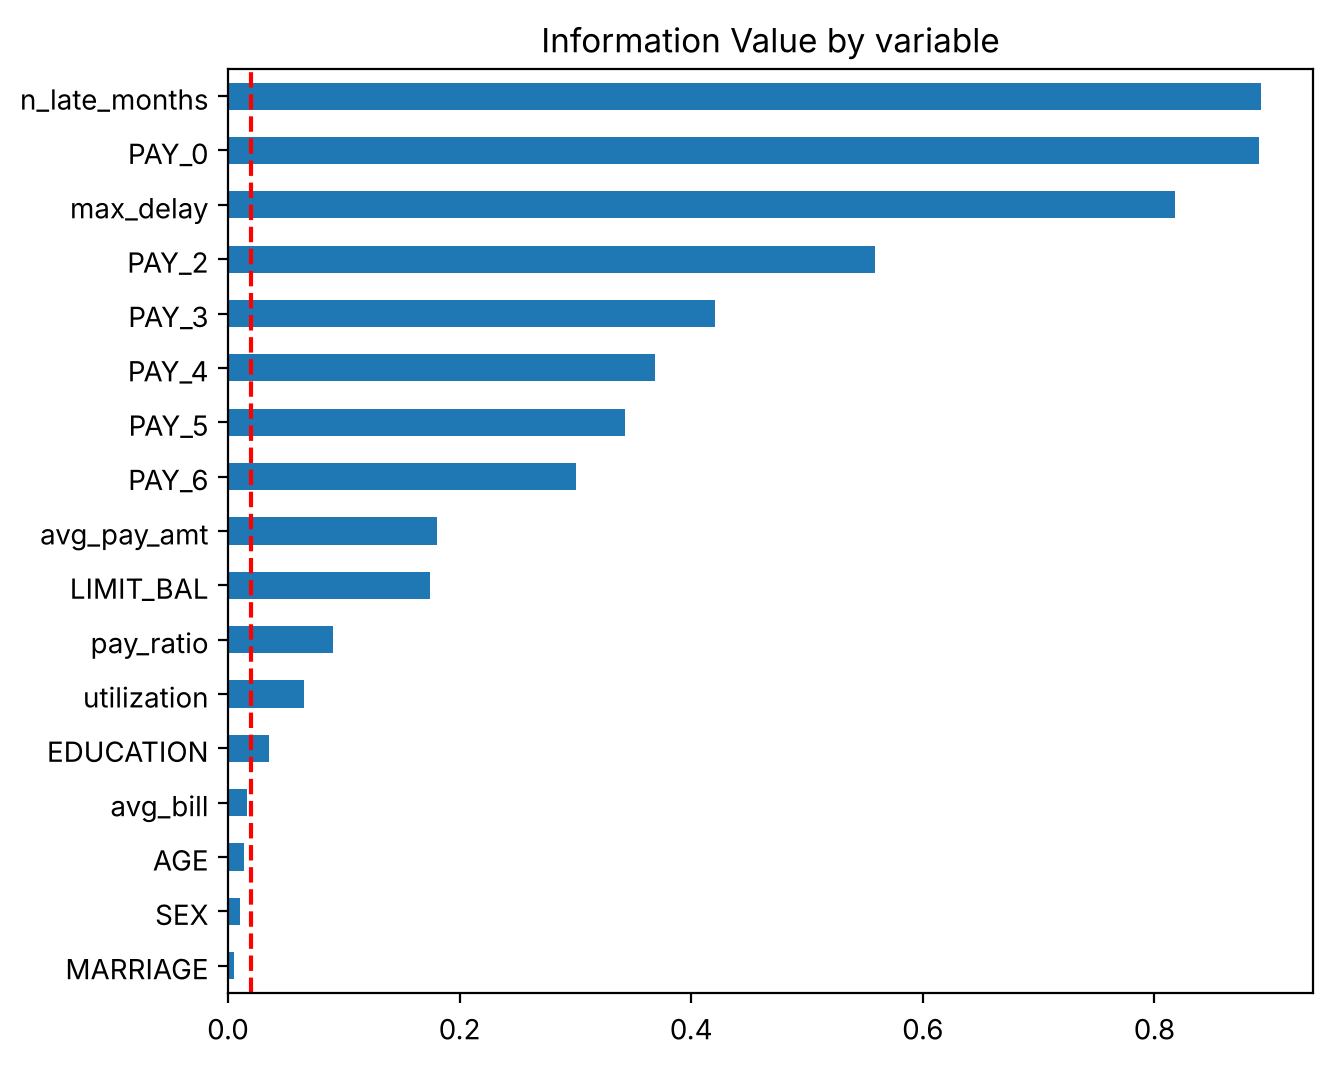

,range,total,bad,bad_rate,woe,iv
bin,,,,,,
-1,-1,5904,918,0.155,0.433,0.046
0,0,10285,1300,0.126,0.675,0.182
1,1,2616,895,0.342,-0.605,0.053
2,2,1887,1311,0.695,-2.080,0.514
3,3,213,163,0.765,-2.433,0.078
4,4,95,58,0.611,-1.703,0.018


In [ ]:
iv_df['IV'][::-1].plot(kind='barh', figsize=(7, 6))
plt.axvline(0.02, color='red', linestyle='--')
plt.title('Information Value by variable')
plt.show()

# looking at one table to check the binning makes sense
maps['PAY_0']['table'][['range', 'total', 'bad', 'bad_rate', 'woe', 'iv']]

Selection rules I am using:

1. Keep variables with IV >= 0.02
2. Many variables are highly correlated (e.g. `PAY_0` and `max_delay`, or the different bill months). For correlated pairs I keep the one with the higher IV, using a correlation cut-off of 0.7 on the WoE values. This avoids multicollinearity in the logistic regression and keeps the coefficients easier to explain.

In [ ]:
def to_woe(data, cols):
    return pd.DataFrame({c: apply_woe(data[c], maps[c]) for c in cols})

selected = iv_df[iv_df['IV'] >= 0.02].index.tolist()    # already sorted by IV, highest first
corr = to_woe(train, selected).corr().abs()

keep = []
for c in selected:
    if all(corr.loc[c, k] < 0.7 for k in keep):
        keep.append(c)

print('kept   :', keep)
print('dropped:', [c for c in candidates if c not in keep])

kept   : ['n_late_months', 'PAY_5', 'PAY_6', 'avg_pay_amt', 'LIMIT_BAL', 'pay_ratio', 'utilization', 'EDUCATION']
dropped: ['AGE', 'SEX', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'max_delay', 'avg_bill']


## 7. Logistic regression PD model

Logistic regression on the WoE-transformed variables. I used this instead of something like XGBoost because banks and regulators need models they can explain, and a scorecard built from logistic regression can be read line by line.

Since WoE is defined as ln(good/bad), a higher WoE means safer, so **all the coefficients should come out negative**. If one is positive it does not make business sense (it would say that riskier behaviour lowers the PD), and it usually happens because of leftover correlation between variables. So I drop the variable with the most positive coefficient and refit, until all signs are sensible.

In [ ]:
y_train, y_test = train['default'], test['default']

# fit, then drop any variable with a positive coefficient (wrong sign) and refit until all are negative
final_vars = keep.copy()
while True:
    X_train = to_woe(train, final_vars)
    logit = LogisticRegression(max_iter=1000)
    logit.fit(X_train, y_train)
    coefs = pd.Series(logit.coef_[0], index=final_vars)
    if (coefs < 0).all():
        break
    worst = coefs.idxmax()
    print('dropping', worst, '(coef =', round(coefs[worst], 3), ')')
    final_vars.remove(worst)

keep = final_vars
X_train, X_test = to_woe(train, keep), to_woe(test, keep)

print(coefs)
print('intercept:', round(logit.intercept_[0], 3))
print('all coefficients negative?', bool((coefs < 0).all()))

dropping PAY_5 (coef = 0.078 )
dropping PAY_6 (coef = 0.112 )
dropping pay_ratio (coef = 0.023 )
n_late_months   -0.913
avg_pay_amt     -0.516
LIMIT_BAL       -0.161
utilization     -0.448
EDUCATION       -0.334
dtype: float64
intercept: -1.257
all coefficients negative? True


## 8. Converting PD into a credit score

Scorecards give points instead of probabilities. The usual convention is:

- base score of 600 at good:bad odds of 20:1
- every 20 points (PDO = points to double the odds) doubles the good:bad odds

`factor = PDO / ln(2)`, `offset = base_score - factor x ln(base_odds)`, and `score = offset + factor x ln(good/bad odds)`.

These numbers are just a convention, they do not change the ranking of customers.

In [ ]:
pdo, base_score, base_odds = 20, 600, 20
factor = pdo / np.log(2)
offset = base_score - factor * np.log(base_odds)

def get_pd(X):
    return logit.predict_proba(X)[:, 1]

def get_score(X):
    log_odds_bad = logit.decision_function(X)
    return pd.Series(offset - factor * log_odds_bad, index=X.index)

train_score, test_score = get_score(X_train), get_score(X_test)
train_pd, test_pd = pd.Series(get_pd(X_train), index=X_train.index), pd.Series(get_pd(X_test), index=X_test.index)

print(test_score.describe())

count   9,000.000
mean      556.610
std        27.744
min       480.228
25%       536.029
50%       566.719
75%       576.461
max       601.828
dtype: float64


In [ ]:
# points table: how many points each bin of each variable gets (this is the actual 'scorecard')
n = len(keep)
rows = []
for c in keep:
    t = maps[c]['table']
    for b in t.index:
        pts = offset / n - factor * (coefs[c] * t.loc[b, 'woe'] + logit.intercept_[0] / n)
        rows.append({'variable': c, 'bin': t.loc[b, 'range'], 'bad_rate': t.loc[b, 'bad_rate'], 'points': round(pts)})

scorecard = pd.DataFrame(rows)
scorecard

,variable,bin,bad_rate,points
0,n_late_months,0,0.115,131
1,n_late_months,1,0.299,99
2,n_late_months,2,0.397,88
3,n_late_months,3,0.504,76
4,n_late_months,4,0.582,68
5,n_late_months,5,0.617,64
6,n_late_months,6,0.698,55
7,avg_pay_amt,"(-inf, 771.97]",0.311,103
8,avg_pay_amt,"(771.97, 1,446.17]",0.292,104
9,avg_pay_amt,"(1,446.17, 2,416.67]",0.252,107


Reading this table: for a variable like `PAY_0`, bins with a high bad rate get fewer points and clean bins get more points. Adding up the points of the bins a customer falls in gives the final score (it may differ by a few points from the exact score above due to rounding).

## 9. Model validation

- **AUC**: probability the model ranks a random bad customer as riskier than a random good one (0.5 = random)
- **Gini** = 2 x AUC - 1, the number banks usually quote
- **KS**: maximum gap between the cumulative bad and good distributions. Around 0.3-0.5 is considered decent for retail credit
- **PSI** (population stability index): checks if the score distribution has shifted between two samples. Rule of thumb: < 0.1 stable, 0.1-0.25 some shift, > 0.25 big shift

Comparing train vs test also shows if the model is overfitting.

In [ ]:
def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return (tpr - fpr).max()

def psi(expected, actual, edges):
    e = np.histogram(expected, bins=edges)[0] / len(expected)
    a = np.histogram(actual, bins=edges)[0] / len(actual)
    e, a = np.clip(e, 1e-4, None), np.clip(a, 1e-4, None)
    return np.sum((a - e) * np.log(a / e))

auc_tr, auc_te = roc_auc_score(y_train, train_pd), roc_auc_score(y_test, test_pd)

metrics = pd.DataFrame({
    'train': [auc_tr, 2 * auc_tr - 1, ks_stat(y_train, train_pd)],
    'test': [auc_te, 2 * auc_te - 1, ks_stat(y_test, test_pd)]
}, index=['AUC', 'Gini', 'KS'])
print(metrics)

# psi on score deciles (train is the reference)
edges = np.percentile(train_score, np.linspace(0, 100, 11))
edges[0], edges[-1] = -np.inf, np.inf
print('\nPSI train vs test:', round(psi(train_score, test_score, edges), 4))

      train  test
AUC   0.761 0.750
Gini  0.522 0.500
KS    0.417 0.390

PSI train vs test: 0.001


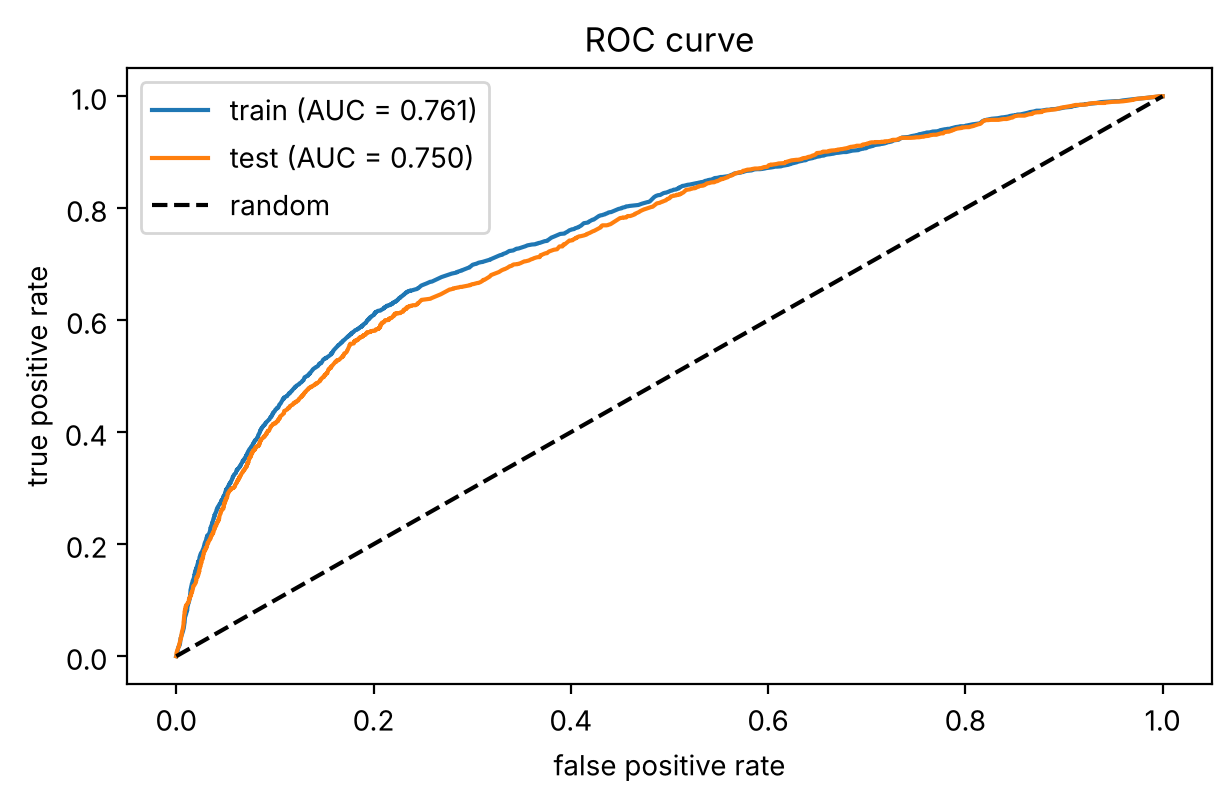

In [ ]:
for name, yy, pp in [('train', y_train, train_pd), ('test', y_test, test_pd)]:
    fpr, tpr, _ = roc_curve(yy, pp)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(yy, pp):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='random')
plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.title('ROC curve')
plt.legend()
plt.show()

Since train and test come from a random split, PSI should be close to 0 here. It becomes useful in real life when comparing the development sample with *new* customers months later. A high PSI would tell the bank that the model needs a review.

One limitation: I have no time dimension in this dataset, so there is no proper out-of-time validation.

## 10. Risk grades

Customers are grouped into 5 grades (A = safest, E = riskiest) using score cut points from the training data. A good scorecard should show the bad rate going up steadily as we move from A to E (called rank ordering).

In [ ]:
_, band_edges = pd.qcut(train_score, 5, retbins=True)
band_edges[0], band_edges[-1] = -np.inf, np.inf
grade_labels = ['E', 'D', 'C', 'B', 'A']      # lowest scores are the riskiest

test_grade = pd.cut(test_score, bins=band_edges, labels=grade_labels)

grade_tbl = pd.DataFrame({'grade': test_grade, 'default': y_test, 'PD': test_pd}) \
              .groupby('grade', observed=True).agg(customers=('default', 'count'),
                                                   avg_pd=('PD', 'mean'),
                                                   actual_default_rate=('default', 'mean')) \
              .sort_index(ascending=True)
grade_tbl

,customers,avg_pd,actual_default_rate
grade,,,
E,1814,0.525,0.509
D,1759,0.248,0.242
C,1808,0.139,0.178
B,1814,0.109,0.099
A,1805,0.078,0.078


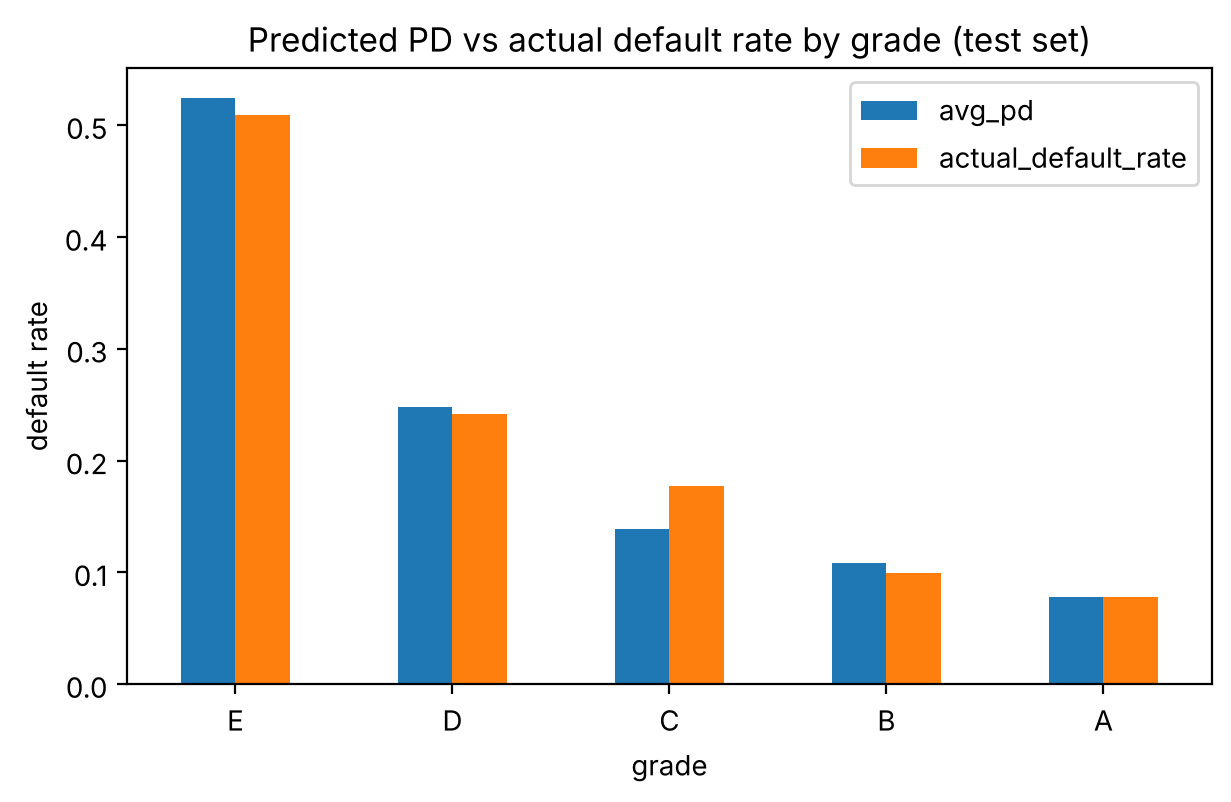

In [ ]:
grade_tbl[['avg_pd', 'actual_default_rate']].plot(kind='bar', figsize=(7, 4))
plt.ylabel('default rate')
plt.title('Predicted PD vs actual default rate by grade (test set)')
plt.xticks(rotation=0)
plt.show()

## 11. Expected Loss = PD x LGD x EAD

- **PD** comes from the model
- **LGD**: this dataset has no recovery data, so I have to *assume* it. I used 75% which is in the range that is often used for unsecured retail (credit card) loans. This is an assumption and not an estimate from data
- **EAD**: the amount outstanding if the customer defaults. For a credit card it is the drawn balance plus a part of the unused limit (since customers can draw more before defaulting). I used `EAD = drawn + CCF x undrawn` with CCF = 20%, again an assumption. Drawn amount is the latest bill, capped between 0 and the limit

Expected loss is what a bank expects to lose on average, and this is what provisions and pricing should cover. Unexpected loss (the bad-year losses above the average) is what capital is held against, but I haven't modelled that here.

Amounts are in NT$ and I do this on the test set, treating it as the portfolio.

In [ ]:
LGD = 0.75
CCF = 0.20

port = df.loc[test.index, ['LIMIT_BAL', 'BILL_AMT1', 'default']].copy()
port['score'] = test_score
port['PD'] = test_pd
port['grade'] = test_grade

drawn = port['BILL_AMT1'].clip(lower=0, upper=port['LIMIT_BAL'])
undrawn = port['LIMIT_BAL'] - drawn
port['EAD'] = drawn + CCF * undrawn
port['EL'] = port['PD'] * LGD * port['EAD']
port['actual_loss'] = port['default'] * LGD * port['EAD']     # rough 'what really happened' number for comparison

el_tbl = port.groupby('grade', observed=True).agg(customers=('PD', 'count'),
                                                  avg_pd=('PD', 'mean'),
                                                  EAD_mn=('EAD', lambda s: s.sum() / 1e6),
                                                  EL_mn=('EL', lambda s: s.sum() / 1e6),
                                                  actual_loss_mn=('actual_loss', lambda s: s.sum() / 1e6)).sort_index()
el_tbl['EL_rate'] = el_tbl['EL_mn'] / el_tbl['EAD_mn']

total = el_tbl[['customers', 'EAD_mn', 'EL_mn', 'actual_loss_mn']].sum()
total['avg_pd'] = port['PD'].mean()
total['EL_rate'] = total['EL_mn'] / total['EAD_mn']
el_tbl.loc['Total'] = total
el_tbl['customers'] = el_tbl['customers'].astype(int)
el_tbl

,customers,avg_pd,EAD_mn,EL_mn,actual_loss_mn,EL_rate
grade,,,,,,
E,1814,0.525,94.598,36.811,38.369,0.389
D,1759,0.248,102.350,19.537,21.593,0.191
C,1808,0.139,91.855,9.502,11.644,0.103
B,1814,0.109,167.163,13.548,12.101,0.081
A,1805,0.078,208.253,12.331,14.663,0.059
Total,9000,0.220,664.219,91.729,98.370,0.138


Things to check in this table:

- EL rate should rise from grade A to E
- the share of total EL coming from the riskiest grades is much bigger than their share of customers, which is why banks watch these segments closely
- predicted EL should be roughly in line with the rough actual loss. A big gap would mean the PD model is mis-calibrated, or that my LGD / EAD assumptions are off

## 12. Cutoff policy

The business question: **below what score should the bank decline new applications?** A higher cutoff means fewer bad customers but also fewer customers overall (lost revenue). I check a range of cutoffs and look at the approval rate, bad rate and EL rate among the approved customers.

In [ ]:
cutoffs = np.round(np.percentile(port['score'], np.arange(0, 65, 5)))

rows = []
for c in cutoffs:
    ok = port[port['score'] >= c]
    rows.append({'cutoff': c,
                 'approval_rate': len(ok) / len(port),
                 'bad_rate_approved': ok['default'].mean(),
                 'EL_rate_approved': ok['EL'].sum() / ok['EAD'].sum()})
policy = pd.DataFrame(rows)
policy

,cutoff,approval_rate,bad_rate_approved,EL_rate_approved
0,480.000,1.000,0.221,0.138
1,497.000,0.951,0.199,0.127
2,512.000,0.901,0.178,0.114
3,525.000,0.849,0.161,0.103
4,531.000,0.800,0.149,0.097
5,536.000,0.750,0.137,0.091
6,545.000,0.701,0.126,0.082
7,558.000,0.658,0.122,0.078
8,562.000,0.592,0.117,0.075
9,564.000,0.560,0.114,0.074


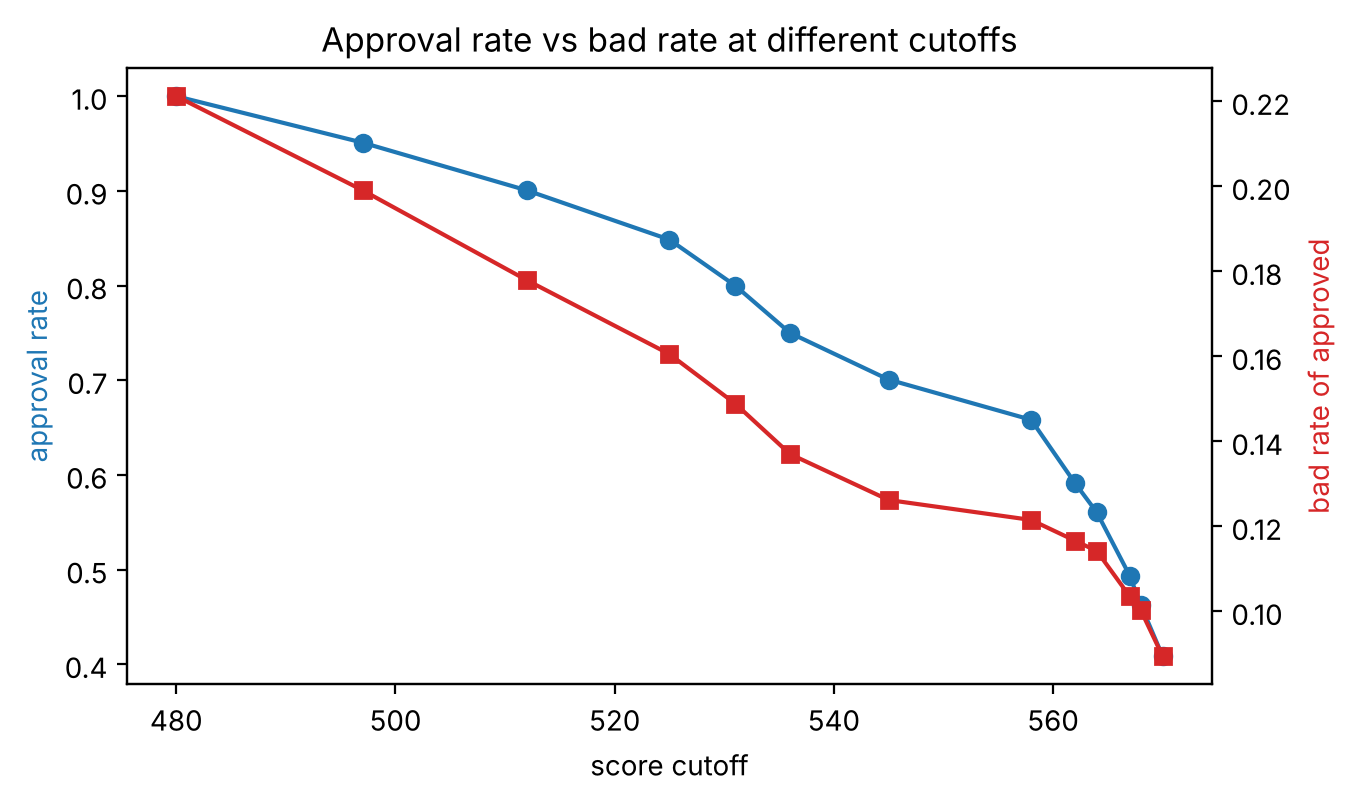

In [ ]:
fig, ax1 = plt.subplots()
ax1.plot(policy['cutoff'], policy['approval_rate'], marker='o', color='tab:blue')
ax1.set_xlabel('score cutoff')
ax1.set_ylabel('approval rate', color='tab:blue')
ax2 = ax1.twinx()
ax2.plot(policy['cutoff'], policy['bad_rate_approved'], marker='s', color='tab:red')
ax2.set_ylabel('bad rate of approved', color='tab:red')
plt.title('Approval rate vs bad rate at different cutoffs')
plt.show()

In [ ]:
# picking the lowest cutoff (most approvals) that keeps the bad rate under a target
TARGET_BAD_RATE = 0.15

ok_rows = policy[policy['bad_rate_approved'] <= TARGET_BAD_RATE]
if len(ok_rows) > 0:
    best = ok_rows.sort_values('approval_rate', ascending=False).iloc[0]
    print(f"Suggested cutoff: {best['cutoff']:.0f}")
    print(f"Approval rate: {best['approval_rate']:.1%}")
    print(f"Bad rate among approved: {best['bad_rate_approved']:.1%} (portfolio: {port['default'].mean():.1%})")
    print(f"EL rate among approved: {best['EL_rate_approved']:.2%}")
else:
    print('no cutoff in the grid reaches the target bad rate, try a lower target or a higher cutoff')

Suggested cutoff: 531
Approval rate: 80.0%
Bad rate among approved: 14.9% (portfolio: 22.1%)
EL rate among approved: 9.68%


The target bad rate of 15% is my own choice for the exercise. In a real bank it would come from the risk appetite statement and from profitability (interest income vs expected loss and cost). I haven't modelled profit, so this is only a one-sided view.

## 13. Simple stress test

Banks have to check what happens in a bad economy. I do a very simple version: multiply every customer's PD by a factor (1.25x and 1.5x, capped at 100%) and recompute expected loss. LGD and EAD are kept the same, which is a simplification since LGD normally gets worse in recessions too.

In [ ]:
scenarios = {'baseline': 1.0, 'mild stress (PD x1.25)': 1.25, 'severe stress (PD x1.5)': 1.5}

stress = {}
for name, mult in scenarios.items():
    stressed_el = np.clip(port['PD'] * mult, 0, 1) * LGD * port['EAD']
    stress[name] = stressed_el.groupby(port['grade'], observed=True).sum() / 1e6

stress = pd.DataFrame(stress).sort_index()
stress.loc['Total'] = stress.sum()
stress['increase_vs_base_%'] = (stress['severe stress (PD x1.5)'] / stress['baseline'] - 1) * 100
stress

,baseline,mild stress (PD x1.25),severe stress (PD x1.5),increase_vs_base_%
grade,,,,
E,36.811,46.013,54.713,48.634
D,19.537,24.422,29.306,50.000
C,9.502,11.878,14.253,50.000
B,13.548,16.935,20.322,50.000
A,12.331,15.414,18.497,50.000
Total,91.729,114.661,137.090,49.452


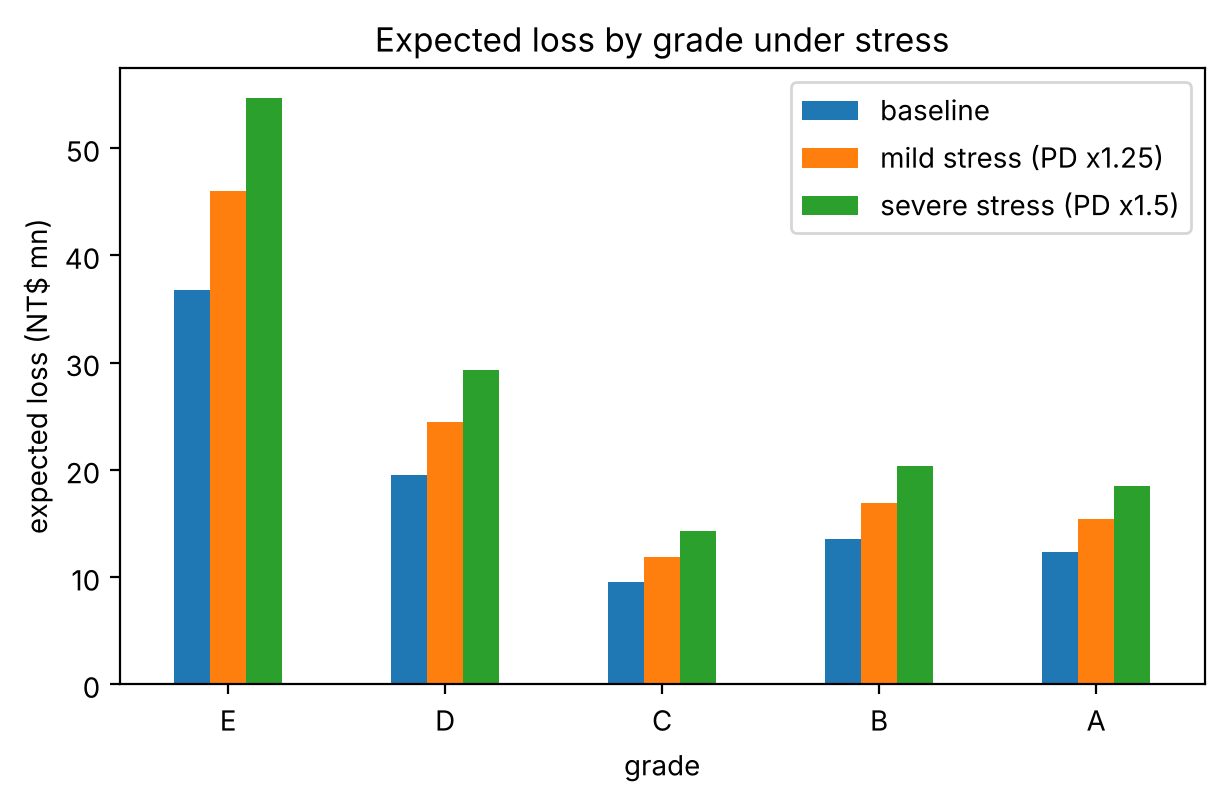

In [ ]:
stress.drop(columns='increase_vs_base_%').drop('Total').plot(kind='bar', figsize=(7, 4))
plt.ylabel('expected loss (NT$ mn)')
plt.title('Expected loss by grade under stress')
plt.xticks(rotation=0)
plt.show()

## 14. Summary of results

In [ ]:
print('Portfolio default rate (test)    :', f"{y_test.mean():.1%}")
print('Gini (test)                      :', f"{metrics.loc['Gini', 'test']:.3f}")
print('KS (test)                        :', f"{metrics.loc['KS', 'test']:.3f}")
print('Variables in the final scorecard :', len(keep), keep)
print('Total expected loss (NT$ mn)     :', f"{el_tbl.loc['Total', 'EL_mn']:,.1f}", 'on EAD of', f"{el_tbl.loc['Total', 'EAD_mn']:,.1f}")
print('EL rate                          :', f"{el_tbl.loc['Total', 'EL_rate']:.2%}")
print('EL under severe stress           :', f"{stress.loc['Total', 'severe stress (PD x1.5)']:,.1f}", 'NT$ mn')

Portfolio default rate (test)    : 22.1%
Gini (test)                      : 0.500
KS (test)                        : 0.390
Variables in the final scorecard : 5 ['n_late_months', 'avg_pay_amt', 'LIMIT_BAL', 'utilization', 'EDUCATION']
Total expected loss (NT$ mn)     : 91.7 on EAD of 664.2
EL rate                          : 13.81%
EL under severe stress           : 137.1 NT$ mn


## 15. Limitations and what I would do next

- **LGD and CCF are assumptions.** The dataset has no recovery or drawdown data, so EL is only as good as these numbers. A real LGD model would use workout and recovery history
- **Default definition.** The target is next month's default flag, not the Basel 90 days past due definition, and it is a 1-month horizon, not 12 months
- **Old, single-country data** (Taiwan 2005, around the card debt crisis), so I can't claim the results generalise
- **No out-of-time validation**, only a random split, so PSI here is not very informative
- **Stress test is crude.** It does not link PD to macro variables (GDP, unemployment) as a proper econometric model would
- **Fairness.** Variables like SEX, MARRIAGE and AGE are used in the candidate list for learning purposes. In practice using some of these would be restricted by regulation or policy and I would check for it

Next steps I would try: IFRS 9 staging (stage 1/2/3 with lifetime ECL), a calibration check on the PD (e.g. Hosmer-Lemeshow or calibration plot), comparing with a gradient boosting model to see how much predictive power is lost for interpretability, and a macro-linked stress test.